This notebook compares the energetic efficiency of two swimming styles: continuous and intermittent swimming.
It loads the CFD simulation results of fish at various length {0.25,0.5,0.75,1}cm which were simulated to be swimming at both styles.
The results are then plotted to show the difference in energetic efficiency between the two swimming styles.

In [1]:
import logging

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from omegaconf import OmegaConf
from scipy.stats import shapiro, ttest_ind, mannwhitneyu
# set up logging
logging.basicConfig(level=logging.WARNING)
from matplotlib.ticker import FuncFormatter
from utils import energetics_calculator, calc_dist, get_root_folder, check_simulation

# Custom formatter to display numbers with specific precision
def custom_formatter(x, pos):
    return f'{x:.1f}' # Format to 2 decimal places, adjust as needed

formatter = FuncFormatter(custom_formatter)

In [2]:
cmap = {"intermittent": "#e20512", "continuous": "#005bba"}

main_folder = get_root_folder()
(main_folder / "figs").mkdir(exist_ok=True)
# use custom matplotlib style
plt.style.use(main_folder / "main.mplstyle")

# Load the YAML into a DictConfig
cfg = OmegaConf.load(main_folder / "config.yaml")
cfg.FPS

25000

# Energetic efficiency

all length {0.25,0.5,0.75,1}cm in one plot

In [3]:
# there are 3D models based on two different morphologies: 14dpf and 30dpf
morphs = ("d14", "d30")
res = []

for morph in morphs:
    for out_folder in main_folder.glob(f"{morph}/*/*dpf*/sim/*/frame_*"):
        fname = out_folder / "Eel3d" / "Eel3d_Power_spent_struct_no_0"
        if not fname.is_file():
            continue
    
        ret = check_simulation(fname, out_folder, cfg.FPS)
        if not np.any(ret):
            continue
        
        dpf, fishlen = ret
        en_sim = energetics_calculator(fname)
        # convert from erg to nano joule
        en_sim *= 100

        dist = calc_dist(out_folder)
        dist *= 10 # convert from cm to mm
        res.append((dpf, dist / en_sim, fishlen, out_folder, morph))

df_ef = pd.DataFrame(res, columns=["dpf", "efficiency", "length (mm)", "folder", "morph"])

In [4]:
df_ef["length (mm)"] *= 10 # convert from cm to mm
df_ef["swim style"] = pd.cut(
    df_ef["dpf"],
    bins=[0, 25, 35],
    labels=["continuous", "intermittent"],
)
df_ef.drop(columns=["folder", "dpf"], inplace=True)
df_ef

,efficiency,length (mm),morph,swim style
0,0.783260,2.5,d14,continuous
1,0.840697,2.5,d14,continuous
2,0.826948,2.5,d14,continuous
3,0.941623,2.5,d14,continuous
4,0.943053,2.5,d14,continuous
...,...,...,...,...
185,0.040205,10.0,d30,intermittent
186,0.038220,10.0,d30,intermittent
187,0.041860,10.0,d30,intermittent
188,0.034761,10.0,d30,intermittent


In [5]:
# normalize the efficiency by the maximum between the two swim styles in each length
df_ef["norm. efficiency"] = df_ef.groupby(["length (mm)", "morph"])["efficiency"].transform(
    lambda x: x / x.mean()
)

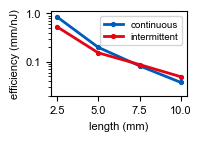

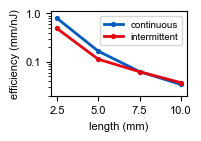

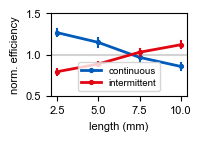

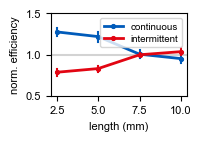

In [6]:
for y_to_plot in ("efficiency", "norm. efficiency"):
    ylim = (0.5, 1.5) if y_to_plot == "norm. efficiency" else (0.02, 1.1)
    ylabel = "norm. efficiency" if y_to_plot == "norm. efficiency" else "efficiency (mm/nJ)"
    yscale = "linear" if y_to_plot == "norm. efficiency" else "log"
    for morph in morphs:
        fig, ax = plt.subplots(figsize=(1.9, 1.3))
        # add a horizontal line at y=1 when plotting normalized efficiency
        if y_to_plot == "norm. efficiency":
            ax.axhline(1, color="#d3d3d3")
        sns.lineplot(
            data=df_ef.query("morph == @morph"),
            x="length (mm)",
            y=y_to_plot,
            hue="swim style",
            palette=cmap,
            linewidth=2,
            err_style="bars",
            errorbar="se",
            # add rounded marker to the line
            marker="o",
            # make edge color of the marker transparent
            markerfacecolor=None,
            markeredgecolor=None,
            markersize=3,
        )
        ax.set(ylim=ylim, ylabel=ylabel, yscale=yscale)
        if yscale == "log":
            ax.yaxis.set_major_formatter(formatter)
        ax.legend(
            fontsize=7,
            # set padding between legend entries
            columnspacing=0.5,
            # set padding between legend title and entries
            labelspacing=0.3,
        )

        fig.savefig(main_folder / "figs" / f"{y_to_plot}_{morph}.svg")

## statistical analysis of the efficiency at different lengths

Perform statistical analysis of efficiency between swim styles at each length

In [7]:
for morph in morphs:
    lengths = sorted(df_ef["length (mm)"].unique())
    results = []

    for length in lengths:
        cot_cont = df_ef.query("morph == @morph and `length (mm)` == @length and `swim style` == 'continuous'")["efficiency"]
        cot_burst = df_ef.query("morph == @morph and `length (mm)` == @length and `swim style` == 'intermittent'")["efficiency"]
        # Only perform test if both groups have at least 2 samples
        if len(cot_cont) > 1 and len(cot_burst) > 1:
            # need to perform normality test first
            # if not normal, use non-parametric test
            if shapiro(cot_cont).pvalue < 0.05 or shapiro(cot_burst).pvalue < 0.05:
                stat, pval = mannwhitneyu(cot_cont, cot_burst)
            else:
                stat, pval = ttest_ind(cot_cont, cot_burst, equal_var=False)
        else:
            stat, pval = float('nan'), float('nan')
        results.append({
            "length (mm)": length,
            "cont_mean": cot_cont.mean(),
            "burst_mean": cot_burst.mean(),
            # "t_stat": stat,
            "p_value": pval,
            # "n_cont": len(cot_cont),
            # "n_burst": len(cot_burst),
        })

    df_stats = pd.DataFrame(results)
    display(morph)
    with pd.option_context('display.float_format', '{:0.2f}'.format):
        display(df_stats)

'd14'

,length (mm),cont_mean,burst_mean,p_value
0,2.50,0.85,0.53,0.00
1,5.00,0.20,0.15,0.00
2,7.50,0.08,0.09,0.38
3,10.00,0.04,0.05,0.00


'd30'

,length (mm),cont_mean,burst_mean,p_value
0,2.50,0.79,0.49,0.00
1,5.00,0.17,0.11,0.00
2,7.50,0.06,0.06,0.60
3,10.00,0.03,0.04,0.26


# Fig 2d, e

## Intermittent swimming

### Power

Energy spent in total: 0.09232499309110903 erg


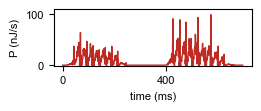

In [8]:
t0, t1 = 343, 717
age, fish_id = "22dpf", "04112025170248"
parent_folder = main_folder / age / "sim" / fish_id / f"frame_{t0}_{t1}"
assert parent_folder.is_dir(), f"Folder {parent_folder} does not exist"

# Load the simulation power data
fname = parent_folder / "Eel3d" / "Eel3d_Power_spent_struct_no_0"
ibamr_power = np.loadtxt(fname).T

power_spent_x = -1 * (ibamr_power[1] - ibamr_power[4])
power_spent_y = -1 * (ibamr_power[2] - ibamr_power[5])
# Compute energy using trapezoidal integration
t_arr = ibamr_power[0]
E_x = np.trapezoid(power_spent_x, t_arr)
E_y = np.trapezoid(power_spent_y, t_arr)

print(f"Energy spent in total: {E_x + E_y} erg")


df_tmp = pd.DataFrame(
    {
        "t": t_arr + t0 / 250,
        "power": power_spent_x + power_spent_y,
    }
)
df_tmp["power"] *= 100 # convert from erg to nano J

fig, ax = plt.subplots(figsize=(2.5, 1))
start_time, end_time = 2.05, 2.75
df_tmp["t"] = (df_tmp["t"] - start_time) * 1000 # offset and convert to ms
sns.lineplot(data=df_tmp.query("t > 0 and t < 700"), x="t", y="power", color="#bf2b23", linewidth=1)
ax.set(xlabel="time (ms)", ylabel="P (nJ/s)", ylim=(-1, 110), xticks=(0, 400))
fig.savefig(main_folder / "figs" / "burst_power.svg")

### Speed

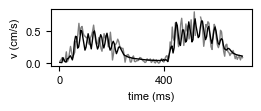

In [9]:
out_folder = parent_folder
FPS: int = cfg.FPS
_, res = calc_dist(out_folder, return_path=True)

with np.load(out_folder / "tmp.npz") as f:
    t_list = f["t_list"]
    t_all = f["t_all"]
    speed_all = f["speed_all"]

# derive age_str, fish_id, t0 and t1 from the out_folder path
rel_path = out_folder.relative_to(main_folder)
age_str, _, fish_id, frame_name = rel_path.parts
_, t0_str, t1_str = frame_name.split("_")
t0, t1 = int(t0_str), int(t1_str)

power_fname = out_folder / "Eel3d" / "Eel3d_Power_spent_struct_no_0"

distances = np.linalg.norm(np.diff(res, axis=0), axis=1)
speed = distances * FPS
# Load the simulation time array
t_arr = np.loadtxt(power_fname, usecols=0)

# calculate moving average of the speed using a window of 20 points
window_size = 50  # moving average window size
df_speed = pd.DataFrame(speed, columns=["speed"])
df_speed["t"] = t_arr[1:] + t_all[t0]
df_speed_avg = df_speed.rolling(window=window_size).mean()


assert t_list[0] == 0, "Time should start at 0"


# get the time of the last frame frome the simulation (which may not have finished)
idx = np.searchsorted(t_list, t_arr[-1])
assert idx <= t1 - t0, "idx should be less than or equal to t1 - t0"
t_ds_clip = t_list[:idx] + t_all[t0]
logging.info(f"simulation: {t_ds_clip[0]:.2f}--{t_ds_clip[-1]:.2f}s")
v2d_ds = speed_all[t0 : t0 + idx]

idx = np.searchsorted(df_speed["t"], t_ds_clip)
df_speed_avg_downsampled = df_speed_avg.iloc[idx]

idx = (df_speed_avg_downsampled["t"] > start_time) * (df_speed_avg_downsampled["t"] < end_time)

fig, ax = plt.subplots(figsize=(2.5, 1))
ax.plot((t_ds_clip[idx] - start_time) * 1000, v2d_ds[idx], label="exp.", color="gray", linewidth=1)
ax.plot(
    (df_speed_avg_downsampled["t"][idx] - start_time) * 1000,
    df_speed_avg_downsampled["speed"][idx],
    label="sim.",
    color="black",
    linewidth=1,
)
ax.set(xlabel="time (ms)", ylabel="v (cm/s)", xticks=(0, 400))

fig.savefig(out_folder / "speed_comp.svg")

## Continuous swimming

### Power

Energy spent in total: 0.34644755938903504 erg


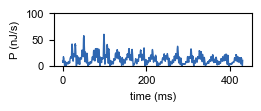

In [10]:
t0, t1 = 0, 540
fish_id, age = "04112025170509", "22dpf"
parent_folder = main_folder / age / "sim" / fish_id / f"frame_{t0}_{t1}"
assert parent_folder.is_dir(), f"Folder {parent_folder} does not exist"

# Load the simulation power data
fname = parent_folder / "Eel3d" / "Eel3d_Power_spent_struct_no_0"
ibamr_power = np.loadtxt(fname).T

power_spent_x = -1 * (ibamr_power[1] - ibamr_power[4])
power_spent_y = -1 * (ibamr_power[2] - ibamr_power[5])
# Compute energy using trapezoidal integration
t_arr = ibamr_power[0]
E_x = np.trapezoid(power_spent_x, t_arr)
E_y = np.trapezoid(power_spent_y, t_arr)

print(f"Energy spent in total: {E_x + E_y} erg")

df_tmp = pd.DataFrame(
    {
        "t": t_arr + t0 / 250,
        "power": power_spent_x + power_spent_y,
    }
)
df_tmp["power"] *= 100 # convert from erg to nano J

start_time, end_time = 1, 1.43
df_tmp["t"] = (df_tmp["t"] - start_time) * 1000 # offset and convert to ms

fig, ax = plt.subplots(figsize=(2.5, 1), constrained_layout=True)
sns.lineplot(data=df_tmp.query("t >0 and t < 430"), x="t", y="power", color="#2f67b1", linewidth=1)
ax.set(xlabel="time (ms)", ylabel="P (nJ/s)", ylim=(0, 100), xticks=(0, 200, 400))

fig.savefig(main_folder / "figs" / "cont_power.svg")

### Speed

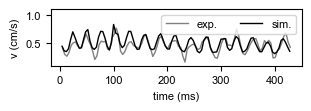

In [11]:
out_folder = parent_folder
FPS: int = cfg.FPS
_, res = calc_dist(out_folder, return_path=True)

with np.load(out_folder / "tmp.npz") as f:
    t_list = f["t_list"]
    t_all = f["t_all"]
    speed_all = f["speed_all"]

# derive age_str, fish_id, t0 and t1 from the out_folder path
rel_path = out_folder.relative_to(main_folder)
age_str, _, fish_id, frame_name = rel_path.parts
_, t0_str, t1_str = frame_name.split("_")
t0, t1 = int(t0_str), int(t1_str)

power_fname = out_folder / "Eel3d" / "Eel3d_Power_spent_struct_no_0"

distances = np.linalg.norm(np.diff(res, axis=0), axis=1)
speed = distances * FPS
# Load the simulation time array
t_arr = np.loadtxt(power_fname, usecols=0)

# calculate moving average of the speed using a window of 20 points
window_size = 50  # moving average window size
df_speed = pd.DataFrame(speed, columns=["speed"])
df_speed["t"] = t_arr[1:] + t_all[t0]
df_speed_avg = df_speed.rolling(window=window_size).mean()


assert t_list[0] == 0, "Time should start at 0"


# get the time of the last frame frome the simulation (which may not have finished)
idx = np.searchsorted(t_list, t_arr[-1])
assert idx <= t1 - t0, "idx should be less than or equal to t1 - t0"
t_ds_clip = t_list[:idx] + t_all[t0]
logging.info(f"simulation: {t_ds_clip[0]:.2f}--{t_ds_clip[-1]:.2f}s")
v2d_ds = speed_all[t0 : t0 + idx]

idx = np.searchsorted(df_speed["t"], t_ds_clip)
df_speed_avg_downsampled = df_speed_avg.iloc[idx]

idx = (df_speed_avg_downsampled["t"] >= start_time) * (df_speed_avg_downsampled["t"] <= end_time)

fig, ax = plt.subplots(figsize=(3, 1), constrained_layout=True)

ax.plot((t_ds_clip[idx] - start_time) * 1000, v2d_ds[idx], label="exp.", color="gray", linewidth=1)
ax.plot(
    (df_speed_avg_downsampled["t"][idx] - start_time) * 1000,
    df_speed_avg_downsampled["speed"][idx],
    label="sim.",
    color="black",
    linewidth=1,
)
ax.legend(ncol=2)
ax.set(xlabel="time (ms)", ylabel="v (cm/s)", ylim=(0.1, 1.1))

fig.savefig(out_folder / "speed_comp.svg")

# Colormap

for Fig. 2c

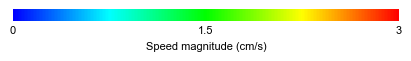

In [12]:
# plot a colorbar for another figure
# https://visit-sphinx-github-user-manual.readthedocs.io/en/develop/using_visit/MakingItPretty/Color_tables.html
# use a continuous colormap which goes from RGB (0, 0, 255) to (0, 255, 255) to (0, 255, 0) to (255, 255, 0) to (255, 0, 0)


from matplotlib.colors import LinearSegmentedColormap

# Define RGB points (normalized to [0, 1])
colors = [
    (0 / 255, 0 / 255, 255 / 255),  # Blue
    (0 / 255, 255 / 255, 255 / 255),  # Cyan
    (0 / 255, 255 / 255, 0 / 255),  # Green
    (255 / 255, 255 / 255, 0 / 255),  # Yellow
    (255 / 255, 0 / 255, 0 / 255),  # Red
]

# Create colormap
custom_cmap = LinearSegmentedColormap.from_list("custom_rainbow", colors, N=256)

# Plot colorbar only
fig, ax = plt.subplots(figsize=(4, 0.5))

cb = plt.colorbar(
    plt.cm.ScalarMappable(cmap=custom_cmap), cax=ax, orientation="horizontal"
)
cb.set_label("Speed magnitude (cm/s)", fontsize=8)
cb.set_ticks([0, 0.5, 1.0])
cb.set_ticklabels(["0", "1.5", "3"], fontsize=8)

# remove the frame of the colorbar
cb.outline.set_visible(False)
# remove the ticks
cb.ax.tick_params(length=0)

[x.patch.set_visible(False) for x in (fig, ax)]
fig.savefig(main_folder / "figs" / "velocity_colorbar.svg", transparent=True)